# Algorithmic Fairness: Invariant Representations via QKeras Bernoulli Activation

This notebook demonstrates a non-edge/FPGA use case for **QKeras**: **Algorithmic Fairness**. Based on the core principles of *"Invariant Representations with Stochastically Quantized Neural Networks"*, we use a stochastic **Bernoulli activation layer** to explicitly compute and minimize the **Mutual Information (MI)** between an internal network representation and a protected sensitive attribute ($S$).

By regularizing our training loss with this information-theoretic term, we force the network to strip away biased structural correlations regarding protected classes while maximizing predicting performance on a target label ($Y$).

### 1. Environment Setup

In [1]:
# !pip install qkeras-v3 keras numpy matplotlib

### 2. Framework Imports & Synthetic Data Profiler

In [2]:
import keras
from keras import ops
from keras.layers import Input, Dense, Activation
from keras.models import Model
from qkeras import QActivation
import numpy as np

def generate_mock_compas(num_samples=2000):
    X = np.random.normal(0, 1, size=(num_samples, 8))
    S = np.random.binomial(n=1, p=0.5, size=(num_samples, 1))
    X += S * 0.5  # Inject algorithmic structural proxy bias

    logits = X[:, 0] * 0.6 + X[:, 1] * -0.4 + S[:, 0] * 0.5
    probs = 1 / (1 + np.exp(-logits))
    Y = np.random.binomial(n=1, p=probs)
    Y = keras.utils.to_categorical(Y, 2)

    return X.astype(np.float32), Y.astype(np.float32), S.astype(np.float32)

X_train, Y_train, S_train = generate_mock_compas(2000)

/Users/mariuskoppel/cms/qkeras/venv/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


### 3. Native Keras 3 Bernoulli Mutual Information Loss Function
This custom loss relies purely on `keras.ops`, ensuring compilation compatibility with JAX XLA JIT compilers and PyTorch autograd graph builders alike.

In [3]:
@keras.saving.register_keras_serializable()
def mutual_information_bernoulli_loss(s_true, z_pred):
    """
        I(x;y)  = H(x)   - H(x|y)
                = H(L_n) - H(L_n|s)
                = H(L_n) - (H(L_n|s=0) + H(L_n|s=1))
        H_bernoulli(x) = -(1-theta) x ln(1-theta) - theta x ln(theta)
        here theta => probability for 1 and 1-theta => probability for 0

        pseudocode:
        def get_h_bernoulli(l):
            theta = np.mean(l, axis=0)
            return -(1-theta) * np.log2(1-theta) - theta * np.log2(theta)

        y_pred = np.random.binomial(n=1, p=0.6, size=[2000, 5])
        y_true = np.random.binomial(n=1, p=0.6, size=[2000])

        y_pred[y_true == 0] = np.random.binomial(n=1, p=0.5, size=[len(y_true[y_true == 0]), 5])
        y_pred[y_true == 1] = np.random.binomial(n=1, p=0.8, size=[len(y_true[y_true == 1]), 5])

        H_L_n = get_h_bernoulli(y_pred)
        H_L_n_s0 = get_h_bernoulli(y_pred[y_true == 0])
        H_L_n_s1 = get_h_bernoulli(y_pred[y_true == 1])

        counts = np.bincount(y_true)

        MI = H_L_n - ((counts[0] / 2000 * H_L_n_s0) + (counts[1] / 2000 * H_L_n_s1))

        return np.sum(MI)

        :param s_true: sensitive attribute
        :param z_pred: output of the layer
        :return: The loss
    """
    s_true = ops.cast(s_true, "float32")
    z_pred = ops.cast(z_pred, "float32")

    # Continuous Sigmoid relaxation for probability mapping
    temperature = 6.0
    p_theta = ops.sigmoid(temperature * z_pred)

    def log2(tensor):
        return ops.log(tensor + 1e-12) / ops.log(2.0)

    # 1. Global continuous state space entropy H(Z)
    mean_theta_global = ops.mean(p_theta, axis=0)
    H_Z = ops.sum(
        -(1.0 - mean_theta_global) * log2(1.0 - mean_theta_global) 
        - mean_theta_global * log2(mean_theta_global)
    )

    total_samples = ops.cast(ops.shape(p_theta)[0], "float32")

    # 2. Compute Conditional Entropy H(Z|S) via matrix masks
    H_Z_given_S = 0.0
    for i in [0.0, 1.0]:
        # Create a broadcastable mask matching the batch shape (batch_size, 1)
        mask = ops.cast(ops.equal(s_true, i), "float32")

        # Calculate the conditional mean probability for group i
        count_i = ops.sum(mask, axis=0)
        mean_theta_i = ops.sum(p_theta * mask, axis=0) / (count_i + 1e-12)

        # Calculate entropy for this specific conditional group
        h_cond = ops.sum(
            -(1.0 - mean_theta_i) * log2(1.0 - mean_theta_i) 
            - mean_theta_i * log2(mean_theta_i)
        )

        # Weight the group entropy by its population proportion
        weight_i = ops.sum(count_i) / total_samples
        H_Z_given_S += weight_i * h_cond

    # 3. Final Mutual Information computation
    MI = H_Z - H_Z_given_S
    return ops.where(ops.isnan(MI), 0.0, MI)

### 4. Constructing and Compiling the Model Pipeline

In [7]:
def build_fair_model(input_dim=8):
    inputs = Input(shape=(input_dim,), name="main_input")

    x = Dense(32, activation="sigmoid", name="dense_1")(inputs)

    # Hidden Stochastic Bottleneck
    x_latent = Dense(16, name="latent")(x)
    bernoulli_out = QActivation("bernoulli", name="bernoulli_layer")(x_latent)

    x = Dense(16, activation="sigmoid", name="dense_3")(bernoulli_out)
    classification_out = Dense(2, activation="softmax", name="task_output")(x)

    return Model(inputs=inputs, outputs=[classification_out, x_latent], name="Keras3_BinaryMI")

model = build_fair_model()

GAMMA = 0.40  # Regularization penalty tuning parameters
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.005),
    loss={
        "task_output": "categorical_crossentropy",
        "latent": mutual_information_bernoulli_loss
    },
    loss_weights={
        "task_output": float(1.0 - GAMMA),
        "latent": float(GAMMA)
    },
    metrics={"task_output": "accuracy"}
)

### 5. Training Loop

In [ ]:
history = model.fit(
    x=X_train,
    y={"task_output": Y_train, "latent": S_train},
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - latent_loss: 0.0183 - loss: 0.4333 - task_output_accuracy: 0.5350 - task_output_loss: 0.7098
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - latent_loss: 0.0048 - loss: 0.4154 - task_output_accuracy: 0.5475 - task_output_loss: 0.6889 
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - latent_loss: 0.0029 - loss: 0.4121 - task_output_accuracy: 0.5640 - task_output_loss: 0.6851 
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - latent_loss: 0.0015 - loss: 0.4114 - task_output_accuracy: 0.5640 - task_output_loss: 0.6843 
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - latent_loss: 0.0014 - loss: 0.4122 - task_output_accuracy: 0.5640 - task_output_loss: 0.6859 
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - latent_loss: 0.0015 - loss: 0.4118 - task_output_accuracy: 0.5640 - task_output_loss: 0.6854 
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - latent_loss: 0.0023 - loss: 0.4124 - task_output_accuracy: 0.5640 - task_

## 6. Sweeping Gamma to Map the Fairness-Accuracy Trade-off

To see how the regularization parameter $\gamma$ affects our model, we will train separate model instances across a spectrum of values: $\gamma \in [0.0, 0.2, 0.4, 0.6, 0.8]$. 

* When $\gamma = 0.0$: The network completely ignores the fairness constraint, maximizing raw accuracy while likely leaking sensitive historical data.
* As $\gamma \to 1.0$: The network aggressively targets demographic independence, stripping information from the latent layer $Z$ even if it costs task accuracy.

In [10]:
import matplotlib.pyplot as plt

# Define the range of gamma values to evaluate
gamma_range = [0.0, 0.2, 0.4, 0.6, 0.8]
accuracy_results = []
mi_leakage_results = []

print("Starting hyperparameter sweep across gamma configurations...\n")

for g in gamma_range:
    print(f"=== Training with Gamma = {g} ===")

    # Rebuild a fresh instance of the model for this step
    sweep_model = build_fair_model(input_dim=8)

    sweep_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.005),
        loss={
            "task_output": "categorical_crossentropy",
            "latent": mutual_information_bernoulli_loss
        },
        loss_weights={
            "task_output": float(1.0 - g),
            "latent": float(g)
        },
        metrics={"task_output": "accuracy"}
    )

    # Train quietly for a few epochs to observe the transition trajectory
    sweep_model.fit(
        x=X_train,
        y={"task_output": Y_train, "latent": S_train},
        epochs=12,
        batch_size=128,
        verbose=0
    )

    # Evaluate final metrics on the training set
    metrics = sweep_model.evaluate(X_train, {"task_output": Y_train, "latent": S_train}, verbose=0)
    acc = metrics[3] # Extract task accuracy index

    # Extract the raw latent layer outputs to explicitly calculate final MI leakage bits
    _, latent_representations = sweep_model.predict(X_train, verbose=0)
    final_mi = mutual_information_bernoulli_loss(S_train, latent_representations).numpy()

    accuracy_results.append(acc)
    mi_leakage_results.append(final_mi)

    print(f"Result -> Accuracy: {acc*100:.2f}%, MI Leakage: {final_mi:.5f} bits\n")

print("Sweep successfully completed!")

Starting hyperparameter sweep across gamma configurations...

=== Training with Gamma = 0.0 ===
Result -> Accuracy: 63.45%, MI Leakage: 0.10848 bits

=== Training with Gamma = 0.2 ===
Result -> Accuracy: 63.30%, MI Leakage: 0.01103 bits

=== Training with Gamma = 0.4 ===
Result -> Accuracy: 64.15%, MI Leakage: 0.00876 bits

=== Training with Gamma = 0.6 ===
Result -> Accuracy: 56.40%, MI Leakage: 0.00239 bits

=== Training with Gamma = 0.8 ===
Result -> Accuracy: 56.40%, MI Leakage: 0.00027 bits

Sweep successfully completed!


### 7. Visualizing the Pareto Frontier Curve

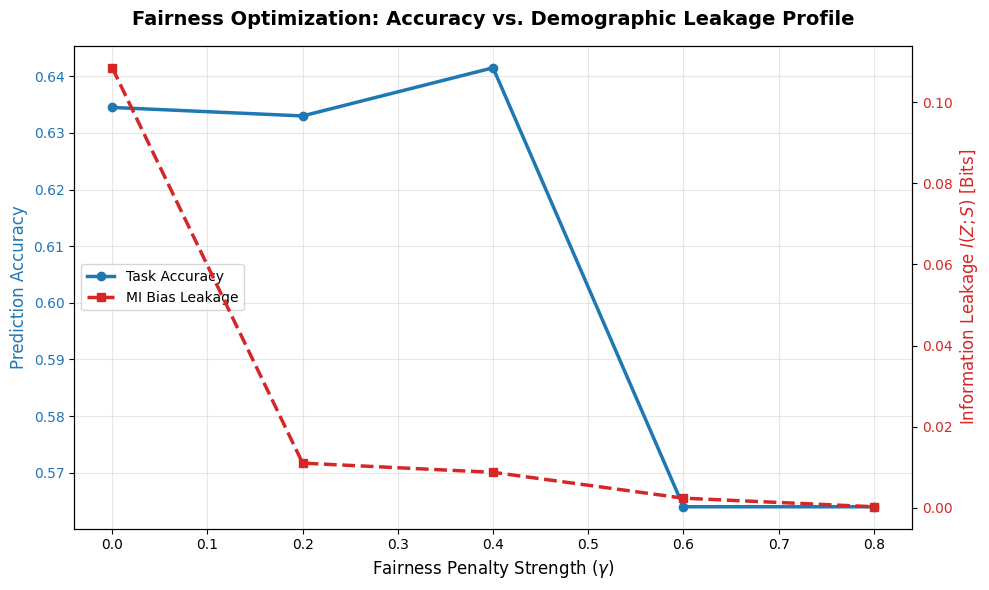

In [11]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: Target Predictive Accuracy
color = 'tab:blue'
ax1.set_xlabel('Fairness Penalty Strength ($\\gamma$)', fontsize=12)
ax1.set_ylabel('Prediction Accuracy', color=color, fontsize=12)
line1 = ax1.plot(gamma_range, accuracy_results, color=color, marker='o', linewidth=2.5, label='Task Accuracy')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

# Instantiate a secondary axis sharing the same x-axis for Mutual Information
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Information Leakage $I(Z; S)$ [Bits]', color=color, fontsize=12)
line2 = ax2.plot(gamma_range, mi_leakage_results, color=color, marker='s', linestyle='--', linewidth=2.5, label='MI Bias Leakage')
ax2.tick_params(axis='y', labelcolor=color)

# Combine annotations into a unified plot legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left')

plt.title('Fairness Optimization: Accuracy vs. Demographic Leakage Profile', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()